In [4]:
import pandas as pd
import unicodedata

df = pd.read_csv("data/routes.csv")
print(len(df), "rows")
df.head()

838 rows


,log_id,logged_on,office,from_town,to_town,route_type
0,LOG-00000,2024-01-01,OFF-07,Imatra.,Ingå,bus
1,LOG-00001,2024-01-01,OFF-06,Harjavalta,Pirkkala,ferry
2,LOG-00002,2024-01-01,OFF-09,Imatra,Lieksa,ferry
3,LOG-00003,2024-01-01,OFF-10,Kankaanpää,Helsingfors,bus
4,LOG-00004,2024-01-01,OFF-09,Villmanstrand,helsingfors,ferry


In [5]:
pd.concat([df.from_town, df.to_town]).value_counts().head()

Orivesi     44
Helsinki    31
Imatra      26
Lieksa      24
Tornio      22
Name: count, dtype: int64

In [6]:
def normalize_town(s):
    s = s.strip().strip(".").strip()
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return s.lower()

all_names = pd.concat([df.from_town, df.to_town])
print(all_names.nunique(), "raw names")
print(all_names.map(normalize_town).nunique(), "normalized names")

650 raw names
177 normalized names


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering

raw = sorted(all_names.unique())

X = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 3),
    lowercase=True,
    strip_accents="unicode",
).fit_transform([s.strip(" .") for s in raw])

labels = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.2,
    metric="cosine",
    linkage="average",
).fit_predict(X.toarray())

print(len(set(labels)), "ML clusters")

groups = pd.DataFrame({"raw": raw, "cluster": labels})
groups["n"] = groups.raw.map(all_names.value_counts())
canon = groups.sort_values("n", ascending=False).groupby("cluster").raw.first().map(normalize_town)
spelling = dict(zip(groups.raw, groups.cluster.map(canon)))

177 ML clusters


In [8]:
SWEDISH = { 
    "abo": "turku",
    "alavo": "alavus",
    "birkala": "pirkkala",
    "bjorneborg": "pori",
    "borga": "porvoo",
    "brahestad": "raahe",
    "esbo": "espoo",
    "fredrikshamn": "hamina",
    "grankulla": "kauniainen",
    "hango": "hanko",
    "helsingfors": "helsinki",
    "hogfors": "karkkila",
    "hyvinge": "hyvinkaa",
    "idensalmi": "iisalmi",
    "ikalis": "ikaalinen",
    "ilmola": "ilmajoki",
    "inga": "inkoo",
    "jakobstad": "pietarsaari",
    "kajana": "kajaani",
    "karleby": "kokkola",
    "kasko": "kaskinen",
    "kervo": "kerava",
    "keuru": "keuruu",
    "kimitoon": "kemionsaari",
    "kristinestad": "kristiinankaupunki",
    "kronoby": "kruunupyy",
    "kumo": "kokemaki",
    "kyrkslatt": "kirkkonummi",
    "lahtis": "lahti",
    "lappo": "lapua",
    "larsmo": "luoto",
    "lojo": "lohja",
    "lovisa": "loviisa",
    "lundo": "lieto",
    "malax": "maalahti",
    "nadendal": "naantali",
    "narpes": "narpio",
    "nykarleby": "uusikaarlepyy",
    "nystad": "uusikaupunki",
    "pargas": "parainen",
    "raseborg": "raasepori",
    "raumo": "rauma",
    "reso": "raisio",
    "s:t karins": "kaarina",
    "s:t michel": "mikkeli",
    "sibbo": "sipoo",
    "sjundea": "siuntio",
    "tammerfors": "tampere",
    "tavastehus": "hameenlinna",
    "tornea": "tornio",
    "traskanda": "jarvenpaa",
    "tusby": "tuusula",
    "uleaborg": "oulu",
    "ulvsby": "ulvila",
    "vanda": "vantaa",
    "vasa": "vaasa",
    "vichtis": "vihti",
    "villmanstrand": "lappeenranta",
    "vora": "voyri",
    "korsholm": "mustasaari",
    "virmo": "mynamaki",
}

def clean(s):
    name = spelling[s]
    return SWEDISH.get(name, name)

print(all_names.map(clean).nunique(), "towns")

116 towns


In [9]:
df["a"] = df.from_town.map(clean)
df["b"] = df.to_town.map(clean)

edges = {tuple(sorted(pair)) for pair in zip(df.a, df.b) if pair[0] != pair[1]}
towns = {t for e in edges for t in e}
print(len(towns), "towns,", len(edges), "connections")

116 towns, 448 connections


In [10]:
deg = pd.Series([t for e in edges for t in e]).value_counts()
print(deg.head(8))
print("Flag: SIGMOID_" + "".join(t[0].upper() for t in deg.head(7).index))

helsinki    39
orivesi     38
tornio      33
lieksa      29
imatra      27
nokia       23
eura        22
narpio      21
Name: count, dtype: int64
Flag: SIGMOID_HOTLINE


In [11]:
import networkx as nx

G = nx.Graph()            
G.add_edges_from(edges)   
print(G.number_of_nodes(), "towns,", G.number_of_edges(), "connections")

top7 = sorted(G.degree, key=lambda x: x[1], reverse=True)[:7]
print(top7)

116 towns, 448 connections
[('helsinki', 39), ('orivesi', 38), ('tornio', 33), ('lieksa', 29), ('imatra', 27), ('nokia', 23), ('eura', 22)]


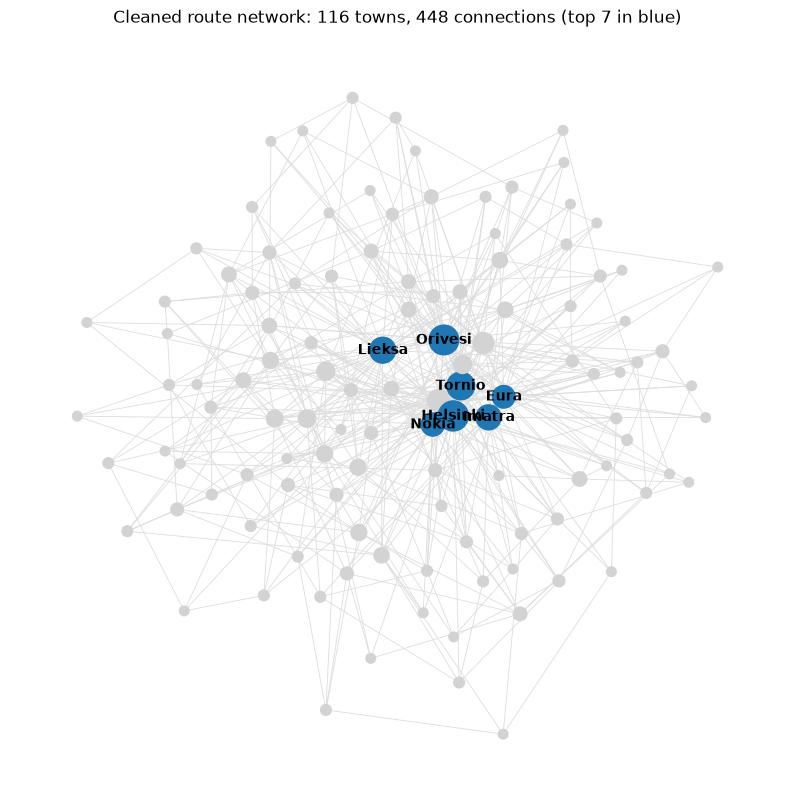

In [15]:
import matplotlib.pyplot as plt

top7 = [t for t, d in sorted(G.degree, key=lambda x: x[1], reverse=True)[:7]]

pos = nx.spring_layout(G, seed=7, k=0.35)   
sizes = [12 * G.degree(t) for t in G]       
colors = ["tab:blue" if t in top7 else "lightgray" for t in G]

plt.figure(figsize=(10, 10))
nx.draw_networkx_edges(G, pos, edge_color="#dddddd", width=0.6)
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors)
nx.draw_networkx_labels(G, pos, labels={t: t.title() for t in top7}, font_size=10, font_weight="bold")
plt.title("Cleaned route network: 116 towns, 448 connections (top 7 in blue)")
plt.axis("off")
plt.show()

